# Actividad 1 · Radar de Oportunidades — carga, EDA y limpieza de PLACSP

**Objetivo.** Pasar de los ficheros mensuales originales de la Plataforma de Contratación del Sector Público (PLACSP) a una capa **silver** limpia de licitaciones TI, que será la entrada de SQL en la Actividad 2.

**Alcance.** Licitaciones con algún CPV de las divisiones **72** (servicios TI) o **48** (paquetes de software), de los ficheros mensuales de **septiembre y octubre de 2026** (sindicación 643, sin contratos menores).

**Orden del notebook:** 1) configuración y carga, 2) diagnóstico y EDA, 3) limpieza, 4) validación, 5) guardado de silver, 6) comparación antes/después.

La ficha de la fuente, las decisiones y las conclusiones están en [`docs/entregas/01_python.md`](../docs/entregas/01_python.md). Las instrucciones para obtener los datos están en [`data/README.md`](../data/README.md).

El notebook se ejecuta de principio a fin sin pasos manuales, siempre que los dos ZIP estén en `data/raw/placsp/`.

## 1. Configuración y carga

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del repositorio, tanto si el notebook se ejecuta desde notebooks/ como desde la raíz.
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

from radar import codigos
from radar.placsp import leer_varios

DIR_RAW = RAIZ / "data" / "raw" / "placsp"
DIR_EXTRAIDO = DIR_RAW / "extraido"      # copia en parquet de lo extraído (regenerable)
DIR_SILVER = RAIZ / "data" / "silver"
DIR_MUESTRAS = RAIZ / "data" / "muestras"
ZIPS = [
    DIR_RAW / "licitacionesPerfilesContratanteCompleto3_202609.zip",
    DIR_RAW / "licitacionesPerfilesContratanteCompleto3_202610.zip",
]
REGENERAR_EXTRACCION = False  # True para volver a leer los ZIP aunque exista la copia extraída

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (8, 4)

faltan = [z.name for z in ZIPS if not z.exists()]
assert not faltan, f"Faltan ZIP en {DIR_RAW}: {faltan}. Ver data/README.md"

### 1.1 Lectura de los ZIP originales

Los ZIP no se modifican nunca: son la copia original. El parser (`src/radar/placsp.py`) lee cada documento Atom **sin descomprimir a disco** y devuelve los valores **como texto, tal cual vienen**. La primera vez tarda varios minutos; después se reutiliza la copia extraída en `data/raw/placsp/extraido/`.

In [2]:
DIR_EXTRAIDO.mkdir(parents=True, exist_ok=True)
rutas_cache = {t: DIR_EXTRAIDO / f"{t}.parquet" for t in ("versiones", "resultados", "borrados")}
ruta_meta = DIR_EXTRAIDO / "meta.json"

if REGENERAR_EXTRACCION or not all(r.exists() for r in rutas_cache.values()):
    datos = leer_varios(ZIPS, solo_ti=True)
    for tabla, ruta in rutas_cache.items():
        datos[tabla].to_parquet(ruta, index=False)
    ruta_meta.write_text(json.dumps(datos["meta"], ensure_ascii=False, indent=2), encoding="utf-8")

raw_versiones = pd.read_parquet(rutas_cache["versiones"]).astype("string")
raw_resultados = pd.read_parquet(rutas_cache["resultados"]).astype("string")
raw_borrados = pd.read_parquet(rutas_cache["borrados"]).astype("string")
meta_lectura = json.loads(ruta_meta.read_text(encoding="utf-8"))
pd.DataFrame(meta_lectura)

,archivo,documentos_atom,entradas_atom,entradas_guardadas,borrados,solo_ti
0,licitacionesPerfilesContratanteCompleto3_20260...,193,95910,7111,218,True
1,licitacionesPerfilesContratanteCompleto3_20261...,124,61638,4657,141,True


In [3]:
for nombre, tabla in [("versiones", raw_versiones), ("resultados", raw_resultados), ("borrados", raw_borrados)]:
    print(f"{nombre:<11} {tabla.shape[0]:>9,} filas x {tabla.shape[1]:>2} columnas")
raw_versiones.head(3)

versiones      11,768 filas x 29 columnas
resultados      8,938 filas x 10 columnas
borrados          359 filas x  4 columnas


,atom_id,updated,titulo,enlace,expediente,estado,organo_nombre,organo_id,tipo_organo,tipo_contrato,subtipo_contrato,importe_sin_iva,importe_con_iva,valor_estimado,moneda,nuts,lugar,duracion,duracion_unidad,cpv_principal,cpvs,procedimiento,urgencia,sistema_contratacion,fin_presentacion_fecha,fin_presentacion_hora,n_lotes,documento,archivo
0,https://contrataciondelestado.es/sindicacion/l...,2026-09-30T18:49:43.421+02:00,El objeto del contrato al que se refiere el pr...,https://contrataciondelestado.es/wps/poc?uri=d...,184/2026 ELABORACION DE CENSOS DE AMIANTO,EV,Alcaldía del Ayuntamiento de Arroyo de la Luz,L01100211,3,2,1,123966.94,150000,123966.94,EUR,ES432,Cáceres,18,MON,90711100,90711100|72310000|90711000|90711500|71200000|8...,9,1,0,2026-07-20,23:59:00,0,licitacionesPerfilesContratanteCompleto3.atom,licitacionesPerfilesContratanteCompleto3_20260...
1,https://contrataciondelestado.es/sindicacion/l...,2026-09-30T18:29:48.287+02:00,"suministro, transporte, instalación, configura...",https://contrataciondelestado.es/wps/poc?uri=d...,544/2026,PUB,Alcaldía del Ayuntamiento de Montanejos,L01120799,3,1,2,59900,72479,59900,EUR,ES522,Castellón/Castelló,<NA>,<NA>,34422000,34422000|48110000|79342000|50110000|34432000,9,1,0,2026-10-10,23:59:00,0,licitacionesPerfilesContratanteCompleto3.atom,licitacionesPerfilesContratanteCompleto3_20260...
2,https://contrataciondelestado.es/sindicacion/l...,2026-09-30T18:10:38.922+02:00,Suministro consistente en el mantenimiento y s...,https://contrataciondelestado.es/wps/poc?uri=d...,2026000778,EV,"Consejería de Presidencia, Reto Demográfico, I...",A03002951,2,1,2,154919.48,187452.57,154919.48,EUR,ES120,Asturias,36,MON,48000000,48000000,1,1,0,2026-09-22,14:00:00,0,licitacionesPerfilesContratanteCompleto3.atom,licitacionesPerfilesContratanteCompleto3_20260...


## 2. Diagnóstico y EDA

Qué representa cada fila en los datos extraídos:
- **versiones**: una versión de un expediente (`atom_id` + `updated`). Un expediente aparece varias veces según cambia de estado.
- **resultados**: un resultado de adjudicación de un lote dentro de una versión (`atom_id` + `updated` + `orden_resultado`).
- **borrados**: un aviso de borrado (*tombstone*) de un expediente.

Todo viene como texto: los tipos se corrigen en la sección 3.

### 2.1 Valores ausentes

In [4]:
def ausentes(tabla: pd.DataFrame) -> pd.DataFrame:
    n = tabla.isna().sum()
    return pd.DataFrame({"nulos": n, "pct": (100 * n / len(tabla)).round(2)}).sort_values("pct", ascending=False)

ausentes(raw_versiones)

,nulos,pct
lugar,899,7.64
fin_presentacion_hora,695,5.91
fin_presentacion_fecha,695,5.91
duracion_unidad,602,5.12
duracion,602,5.12
nuts,32,0.27
subtipo_contrato,17,0.14
sistema_contratacion,6,0.05
atom_id,0,0.00
documento,0,0.00


In [5]:
ausentes(raw_resultados)

,nulos,pct
lote,4548,50.88
importe_adjudicacion_sin_iva,364,4.07
ofertas,77,0.86
atom_id,0,0.00
updated,0,0.00
orden_resultado,0,0.00
resultado,0,0.00
fecha_adjudicacion,0,0.00
documento,0,0.00
archivo,0,0.00


### 2.2 Duplicados y versiones por expediente

In [6]:
clave_version = ["atom_id", "updated"]
dup_exactos = raw_versiones.duplicated().sum()
dup_clave = raw_versiones.duplicated(clave_version).sum()
# ¿Hay versiones con la misma clave pero contenido distinto? (sería un conflicto, no un duplicado)
columnas_contenido = [c for c in raw_versiones.columns if c not in ("documento", "archivo")]
sin_identicos = raw_versiones.drop_duplicates(columnas_contenido)
conflictos = sin_identicos.duplicated(clave_version).sum()
print(f"Filas idénticas: {dup_exactos:,} | misma clave atom_id+updated: {dup_clave:,} | "
      f"misma clave con contenido distinto: {conflictos:,}")

if conflictos:
    en_conflicto = sin_identicos[sin_identicos.duplicated(clave_version, keep=False)]
    cambia = {col: int((en_conflicto.groupby(clave_version)[col].nunique(dropna=False) > 1).sum())
              for col in columnas_contenido}
    print("Campos que cambian entre copias con la misma clave:", {k: n for k, n in cambia.items() if n})

versiones_por_id = raw_versiones.drop_duplicates(clave_version).groupby("atom_id").size()
print(f"Expedientes distintos: {versiones_por_id.size:,}")
versiones_por_id.describe()

Filas idénticas: 0 | misma clave atom_id+updated: 2,346 | misma clave con contenido distinto: 369
Campos que cambian entre copias con la misma clave: {'estado': 348, 'valor_estimado': 1, 'lugar': 2, 'duracion': 1, 'cpvs': 25, 'fin_presentacion_fecha': 22, 'fin_presentacion_hora': 2}
Expedientes distintos: 4,692


count    4692.000000
mean        2.008099
std         1.438847
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        14.000000
dtype: float64

In [7]:
dup_res = raw_resultados.duplicated(["atom_id", "updated", "orden_resultado"]).sum()
print(f"Resultados con la misma clave atom_id+updated+orden: {dup_res:,} (vienen de las versiones repetidas)")

Resultados con la misma clave atom_id+updated+orden: 2,005 (vienen de las versiones repetidas)


### 2.3 Cobertura temporal

Rango de 'updated': 2021-09 a 2026-10
updated
2021-09      95
2026-08     517
2026-09    6507
2026-10    4649


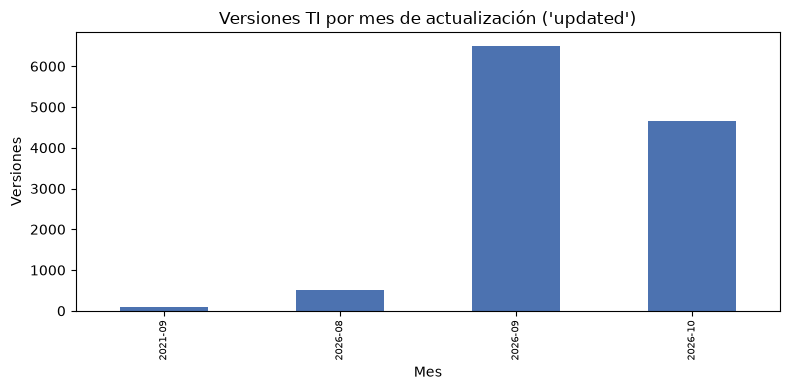

In [8]:
mes_updated = pd.to_datetime(raw_versiones["updated"], utc=True, errors="coerce").dt.strftime("%Y-%m")
cobertura = mes_updated.value_counts().sort_index()
print(f"Rango de 'updated': {cobertura.index.min()} a {cobertura.index.max()}")
print(cobertura.tail(8).to_string())

ax = cobertura.plot(kind="bar", color="#4C72B0")
ax.set_title("Versiones TI por mes de actualización ('updated')")
ax.set_xlabel("Mes")
ax.set_ylabel("Versiones")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

### 2.4 Variables categóricas: estado, procedimiento, tipo de contrato y CPV

In [9]:
# Última versión de cada expediente (de cada versión repetida, la del documento más reciente).
ultima_raw = (raw_versiones.sort_values(["archivo", "documento"]).drop_duplicates(clave_version, keep="last")
              .assign(_t=lambda d: pd.to_datetime(d["updated"], utc=True, errors="coerce"))
              .sort_values("_t").groupby("atom_id").tail(1))

def frecuencias(serie: pd.Series, diccionario: dict) -> pd.DataFrame:
    vc = serie.value_counts(dropna=False)
    return pd.DataFrame({
        "etiqueta": [codigos.etiqueta(diccionario, c) if pd.notna(c) else "(vacío)" for c in vc.index],
        "n": vc.values,
        "pct": (100 * vc.values / vc.sum()).round(1),
    }, index=vc.index)

print("Estado (última versión de cada expediente)")
display(frecuencias(ultima_raw["estado"], codigos.ESTADO))
print("Procedimiento")
display(frecuencias(ultima_raw["procedimiento"], codigos.PROCEDIMIENTO))
print("Tipo de contrato")
display(frecuencias(ultima_raw["tipo_contrato"], codigos.TIPO_CONTRATO))

Estado (última versión de cada expediente)


,etiqueta,n,pct
estado,,,
RES,Resuelta,2408,51.3
EV,Pendiente de adjudicación,810,17.3
ADJ,Adjudicada,745,15.9
PUB,En plazo,680,14.5
PRE,Anuncio previo,37,0.8
ANUL,Anulada,12,0.3


Procedimiento


,etiqueta,n,pct
procedimiento,,,
1,Abierto,2064,44.0
9,Abierto simplificado,1283,27.3
3,Negociado sin publicidad,563,12.0
2,Restringido,563,12.0
100,Normas internas,120,2.6
7,Derivado de acuerdo marco,60,1.3
4,Negociado con publicidad,27,0.6
13,Licitación con negociación,6,0.1
8,Concurso de proyectos,3,0.1


Tipo de contrato


,etiqueta,n,pct
tipo_contrato,,,
2,Servicios,2781,59.3
1,Suministros,1885,40.2
8,Privado,9,0.2
3,Obras,9,0.2
50,Patrimonial,6,0.1
22,Concesión de servicios,2,0.0


In [10]:
divisiones = ultima_raw["cpvs"].str.split("|").explode().str[:2]
ti = divisiones[divisiones.isin(codigos.DIVISIONES_TI)]
print("Expedientes con algún CPV de cada división TI:")
print(ti.groupby(level=0).unique().explode().value_counts().to_string())
print("\nCPV principal más frecuentes:")
ultima_raw["cpv_principal"].value_counts().head(10)

Expedientes con algún CPV de cada división TI:


cpvs
72    3151
48    2101

CPV principal más frecuentes:


cpv_principal
48000000    845
72000000    489
72267000    207
72267100    155
72200000    141
48218000    122
72500000    112
30200000    105
48900000     71
72600000     71
Name: count, dtype: int64[pyarrow]

### 2.5 Importe de licitación

In [11]:
importe = pd.to_numeric(raw_versiones["importe_sin_iva"], errors="coerce")
no_numericos = raw_versiones["importe_sin_iva"].notna() & importe.isna()
print(f"Importes no convertibles a número: {no_numericos.sum():,}")
print(f"Importes <= 0: {(importe <= 0).sum():,}")
print(f"Monedas: {raw_versiones['moneda'].value_counts(dropna=False).to_dict()}")
importe.describe(percentiles=[.01, .25, .5, .75, .99]).round(0)

Importes no convertibles a número: 0
Importes <= 0: 103


Monedas: {'EUR': 11768}


count        11768.0
mean       1107760.0
std        8074670.0
min              0.0
1%             684.0
25%          30845.0
50%          96139.0
75%         324238.0
99%       22312710.0
max      461000000.0
Name: importe_sin_iva, dtype: Float64

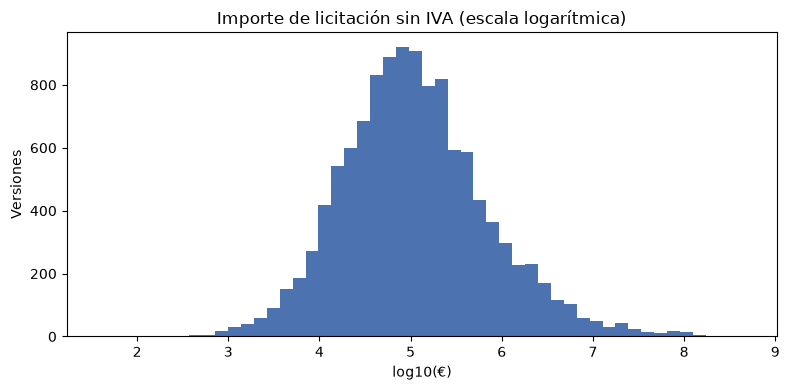

Importes más altos (para revisar si son errores o contratos grandes):


,expediente,titulo,organo_nombre,importe,procedimiento
7970,SDA-TIC/2-21CC,Suministro de Equipos y Material Informático d...,"Conselleria de Economía, Hacienda y Administra...",461000000.0,2
6729,2025/SP03032003/00002230E,Acuerdo Marco de Equipamiento y Servicios para...,Subdirección General de Contratación de Tecnol...,232428774.0,4
7386,DTC-67/2026,Segregación De Entornos Tecnológicos Para Mejo...,Aena. Consejo de Administración,179235034.56,100
6108,2025/JCMDEF/00000105,Acuerdo Marco para la contratación de servicio...,Junta de Contratación del Ministerio de Defensa,168550112.98,4
5378,CON2025000075,Contrato mixto de servicio y obras del servici...,Xunta de Goberno do Concello de Santiago de Co...,128564998.0,1
10632,2026/032169,Servicios de Telecomunicaciones y Cibersegurid...,Secretaría General de la Consejería de Haciend...,95100198.34,1
1614,13058/2025,Contratación Centralizada de Servicios de Comu...,"Consejería de Economía, Hacienda, Portavocía, ...",85243402.69,1
6098,0029293-25,Concesión del servicio de estacionamiento regu...,Gobierno de Zaragoza,81384814.0,1


In [12]:
positivos = importe[importe > 0]
ax = np.log10(positivos).plot(kind="hist", bins=50, color="#4C72B0")
ax.set_title("Importe de licitación sin IVA (escala logarítmica)")
ax.set_xlabel("log10(€)")
ax.set_ylabel("Versiones")
plt.tight_layout()
plt.show()

print("Importes más altos (para revisar si son errores o contratos grandes):")
(raw_versiones.assign(importe=importe).sort_values("importe", ascending=False)
 .drop_duplicates("atom_id")[["expediente", "titulo", "organo_nombre", "importe", "procedimiento"]].head(8))

### 2.6 Resultados por lote y número de ofertas

In [13]:
print("Código de resultado (todas las versiones):")
display(frecuencias(raw_resultados["resultado"], codigos.RESULTADO))

ofertas = pd.to_numeric(raw_resultados["ofertas"], errors="coerce")
print(f"Ofertas no convertibles: {(raw_resultados['ofertas'].notna() & ofertas.isna()).sum():,} | "
      f"negativas: {(ofertas < 0).sum():,} | máximo: {ofertas.max():.0f}")
adjudicado_sin_ofertas = raw_resultados["resultado"].isin(codigos.RESULTADOS_ADJUDICADO) & (ofertas == 0)
print(f"Lotes adjudicados con 0 ofertas (inconsistentes): {adjudicado_sin_ofertas.sum():,}")
desierto_con_ofertas = raw_resultados["resultado"].isin(codigos.RESULTADOS_DESIERTO) & (ofertas > 0)
print(f"Lotes desiertos con ofertas > 0 (posible: ofertas rechazadas): {desierto_con_ofertas.sum():,}")

Código de resultado (todas las versiones):


,etiqueta,n,pct
resultado,,,
9,Formalizado,5012,56.1
8,Adjudicado,3562,39.9
3,Desierto,272,3.0
4,Desistimiento,70,0.8
5,Renuncia,22,0.2


Ofertas no convertibles: 0 | negativas: 0 | máximo: 52
Lotes adjudicados con 0 ofertas (inconsistentes): 0
Lotes desiertos con ofertas > 0 (posible: ofertas rechazadas): 85


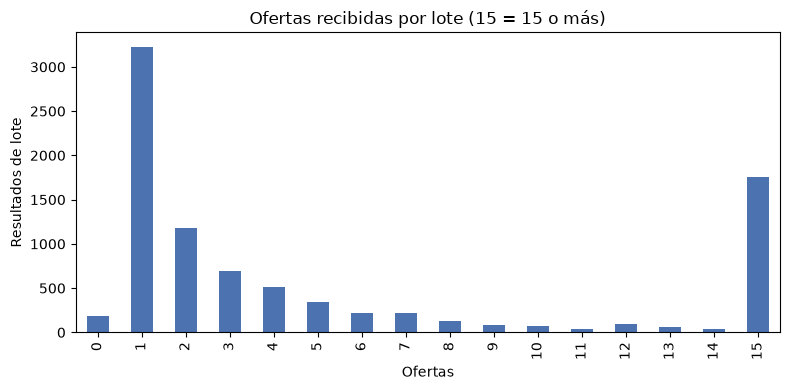

In [14]:
ax = ofertas.clip(upper=15).value_counts().sort_index().plot(kind="bar", color="#4C72B0")
ax.set_title("Ofertas recibidas por lote (15 = 15 o más)")
ax.set_xlabel("Ofertas")
ax.set_ylabel("Resultados de lote")
plt.tight_layout()
plt.show()

### 2.7 Concurrencia en TI según el procedimiento

Primera aproximación a la variable objetivo, usando la **última versión** de cada expediente y solo lotes cerrados (desierto o adjudicado). **Baja concurrencia** = desierto o adjudicado con 0-1 ofertas. Es exploratorio: la definición final del objetivo corresponde a Estadística y ML.

In [15]:
res_ultimos = raw_resultados.merge(ultima_raw[clave_version + ["archivo", "documento", "procedimiento"]],
                                   on=clave_version + ["archivo", "documento"])
res_ultimos["ofertas_n"] = pd.to_numeric(res_ultimos["ofertas"], errors="coerce")
cerrados = res_ultimos[res_ultimos["resultado"].isin(codigos.RESULTADOS_DESIERTO | codigos.RESULTADOS_ADJUDICADO)].copy()
cerrados["baja_concurrencia"] = cerrados["resultado"].isin(codigos.RESULTADOS_DESIERTO) | (cerrados["ofertas_n"] <= 1)

concurrencia = (cerrados.groupby("procedimiento")
                .agg(lotes=("baja_concurrencia", "size"),
                     pct_desiertos=("resultado", lambda s: 100 * s.isin(codigos.RESULTADOS_DESIERTO).mean()),
                     pct_baja_concurrencia=("baja_concurrencia", lambda s: 100 * s.mean()),
                     mediana_ofertas=("ofertas_n", "median"))
                .round(1).sort_values("lotes", ascending=False))
concurrencia.insert(0, "procedimiento_desc", [codigos.etiqueta(codigos.PROCEDIMIENTO, c) for c in concurrencia.index])
display(concurrencia)
no_neg = cerrados[~cerrados["procedimiento"].isin(codigos.PROCEDIMIENTOS_NEGOCIADOS)]
print(f"Total TI: {len(cerrados):,} lotes, {100*cerrados['baja_concurrencia'].mean():.1f} % baja concurrencia | "
      f"sin negociados: {len(no_neg):,} lotes, {100*no_neg['baja_concurrencia'].mean():.1f} %")

,procedimiento_desc,lotes,pct_desiertos,pct_baja_concurrencia,mediana_ofertas
procedimiento,,,,,
1,Abierto,2151,2.7,29.3,3.0
9,Abierto simplificado,854,6.1,43.2,2.0
3,Negociado sin publicidad,562,3.2,95.7,1.0
2,Restringido,521,6.0,43.2,2.0
100,Normas internas,87,8.0,47.1,2.0
7,Derivado de acuerdo marco,61,3.3,60.7,1.0
4,Negociado con publicidad,31,0.0,67.7,1.0
13,Licitación con negociación,6,0.0,16.7,5.0
8,Concurso de proyectos,2,0.0,0.0,11.0


Total TI: 4,275 lotes, 43.6 % baja concurrencia | sin negociados: 3,682 lotes, 35.4 %


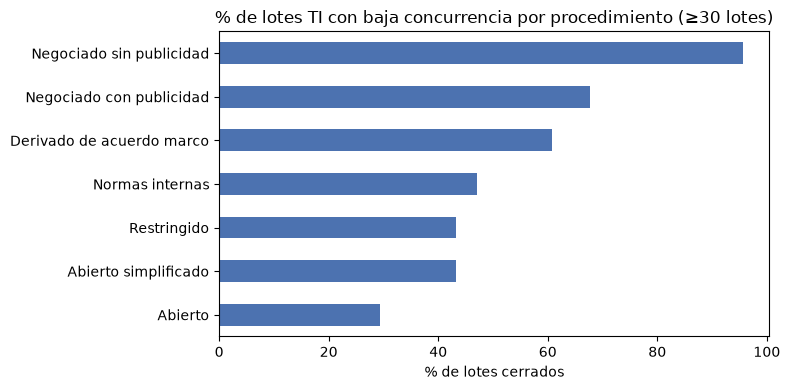

In [16]:
top = concurrencia[concurrencia["lotes"] >= 30]
ax = top.set_index("procedimiento_desc")["pct_baja_concurrencia"].sort_values().plot(kind="barh", color="#4C72B0")
ax.set_title("% de lotes TI con baja concurrencia por procedimiento (≥30 lotes)")
ax.set_xlabel("% de lotes cerrados")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 2.8 Interpretación del diagnóstico

- **Volumen.** Los dos ficheros dan 11.768 versiones de 4.692 expedientes TI (CPV 72 o 48) y 8.938 resultados de lote. Es suficiente para revisar el proceso, pero no para entrenar un modelo fiable: hará falta más histórico.
- **Duplicados.** No hay filas idénticas, pero 2.346 versiones repiten la clave `atom_id` + `updated` porque el mismo cambio aparece en varios documentos Atom del ZIP. En 369 casos el contenido cambia, casi siempre el `estado` (348). Hay que deduplicar quedándose con el documento más reciente.
- **Cobertura temporal.** El fichero de septiembre arrastra versiones antiguas (desde 2021-09); el de octubre solo trae octubre. La mayoría de las versiones son de septiembre y octubre de 2026.
- **Estados.** En su última versión, el 51 % de los expedientes está resuelto y solo el 14,5 % sigue en plazo. Muchos expedientes no tienen su versión en plazo dentro de la muestra, lo que limita el control de fuga de información.
- **Procedimiento.** Dominan el abierto (44 %) y el abierto simplificado (27 %). Los negociados sin publicidad son el 12 % y casi siempre tienen una sola oferta por diseño: hay que tratarlos aparte.
- **Importes.** Muy asimétricos (mediana ≈ 96.000 €, máximo 461 M€): se analizan en escala logarítmica. Hay 103 importes ≤ 0 en bruto, que no son presupuestos válidos. Los importes más altos son acuerdos marco reales, así que no se eliminan: solo se marcan.
- **Resultados.** El 96 % de los resultados son adjudicados o formalizados y solo el 3 % desiertos. Hay 85 lotes desiertos con ofertas > 0, que es posible (ofertas rechazadas o excluidas). No hay adjudicados con 0 ofertas.
- **Concurrencia.** El 43,6 % de los lotes TI tiene baja concurrencia (desierto o ≤ 1 oferta); sin negociados baja al 35,4 %. En el procedimiento abierto es el 29,3 %, con una mediana de 3 ofertas. La variable "baja concurrencia" está mucho más equilibrada que "desierta sí/no" y varía según el procedimiento, lo que indica que hay señal que explicar.
- **Lote.** El identificador de lote falta en el 52,6 % de los resultados: son contratos sin lotes, no un error.

## 3. Limpieza

Cada paso responde a un problema detectado en la sección 2. Se registra cuántas filas afecta. No se elimina ninguna versión salvo los duplicados exactos de clave.

In [17]:
registro = []  # (paso, tabla, filas_antes, filas_despues, afectadas, motivo)

def anotar(paso, tabla, antes, despues, afectadas, motivo):
    registro.append({"paso": paso, "tabla": tabla, "filas_antes": antes, "filas_despues": despues,
                     "afectadas": int(afectadas), "motivo": motivo})

v = raw_versiones.copy()
r = raw_resultados.copy()

**L1 · Duplicados de versión.** El mismo par `atom_id` + `updated` aparece en varios documentos Atom (y en los dos meses, porque el ZIP de octubre empieza el 30/09). En la mayoría de casos el contenido es idéntico. En otros (sección 2.2), PLACSP vuelve a publicar la versión en un documento posterior **con el mismo `updated` pero con el estado actualizado** (por ejemplo, de pendiente de adjudicación a adjudicada). En ambos casos se conserva la copia del **documento más reciente**, que es la publicación vigente, y los resultados de lote se toman de ese mismo documento para que sean coherentes con la versión elegida.

In [18]:
# Los nombres de documento llevan fecha y hora (..._AAAAMMDD_HHMMSS_n.atom): ordenarlos
# por archivo y documento deja al final la publicación más reciente.
antes = len(v)
v = v.sort_values(["archivo", "documento"]).drop_duplicates(clave_version, keep="last")
anotar("L1", "versiones", antes, len(v), antes - len(v),
       f"Versión repetida (atom_id+updated): se conserva el documento más reciente ({conflictos} con estado u otros campos actualizados)")
antes = len(r)
origen = v[clave_version + ["archivo", "documento"]]
r = r.merge(origen, on=clave_version + ["archivo", "documento"], how="inner")
anotar("L1", "resultados", antes, len(r), antes - len(r), "Resultados de copias descartadas de la versión")
pd.DataFrame(registro)

,paso,tabla,filas_antes,filas_despues,afectadas,motivo
0,L1,versiones,11768,9422,2346,Versión repetida (atom_id+updated): se conserv...
1,L1,resultados,8938,6933,2005,Resultados de copias descartadas de la versión


**L2 · Tipos.** Las fechas pasan a `datetime` (UTC para `updated`), los importes y la duración a número decimal y los recuentos a entero. Lo que no se pueda convertir queda como nulo y se cuenta.

In [19]:
v["updated"] = pd.to_datetime(v["updated"], utc=True, errors="coerce")
v["fin_presentacion"] = pd.to_datetime(v["fin_presentacion_fecha"].fillna("") + " " +
                                       v["fin_presentacion_hora"].fillna("00:00:00"), errors="coerce")
v.loc[v["fin_presentacion_fecha"].isna(), "fin_presentacion"] = pd.NaT
for col in ["importe_sin_iva", "importe_con_iva", "valor_estimado", "duracion"]:
    texto = v[col]
    v[col] = pd.to_numeric(texto, errors="coerce")
    anotar("L2", "versiones", len(v), len(v), (texto.notna() & v[col].isna()).sum(), f"{col}: texto no numérico -> nulo")
v["n_lotes"] = pd.to_numeric(v["n_lotes"], errors="coerce").astype("Int64")

r["updated"] = pd.to_datetime(r["updated"], utc=True, errors="coerce")
r["fecha_adjudicacion"] = pd.to_datetime(r["fecha_adjudicacion"], errors="coerce")
texto = r["ofertas"]
r["ofertas"] = pd.to_numeric(texto, errors="coerce").astype("Int64")
anotar("L2", "resultados", len(r), len(r), (texto.notna() & r["ofertas"].isna()).sum(), "ofertas: texto no numérico -> nulo")
r["importe_adjudicacion_sin_iva"] = pd.to_numeric(r["importe_adjudicacion_sin_iva"], errors="coerce")
r["orden_resultado"] = pd.to_numeric(r["orden_resultado"], errors="coerce").astype("Int64")
v.dtypes.to_frame("tipo").T

,atom_id,updated,titulo,enlace,expediente,estado,organo_nombre,organo_id,tipo_organo,tipo_contrato,subtipo_contrato,importe_sin_iva,importe_con_iva,valor_estimado,moneda,nuts,lugar,duracion,duracion_unidad,cpv_principal,cpvs,procedimiento,urgencia,sistema_contratacion,fin_presentacion_fecha,fin_presentacion_hora,n_lotes,documento,archivo,fin_presentacion
tipo,string,"datetime64[us, UTC]",string,string,string,string,string,string,string,string,string,Float64,Float64,Float64,string,string,string,Int64,string,string,string,string,string,string,string,string,Int64,string,string,datetime64[us]


**L3 · Valores imposibles y atípicos.** Un importe de licitación ≤ 0 o un número de ofertas negativo son errores: pasan a nulo y se marcan. Los importes muy altos **no se eliminan**: pueden ser contratos grandes reales, así que solo se marcan como atípicos (por encima del percentil 99,9).

In [20]:
imposible = v["importe_sin_iva"] <= 0
v["importe_invalido"] = imposible.fillna(False)
v.loc[imposible.fillna(False), "importe_sin_iva"] = np.nan
anotar("L3", "versiones", len(v), len(v), imposible.sum(), "importe_sin_iva <= 0 -> nulo y marcado")

umbral_atipico = v["importe_sin_iva"].quantile(0.999)
v["importe_atipico"] = (v["importe_sin_iva"] > umbral_atipico).fillna(False)
anotar("L3", "versiones", len(v), len(v), v["importe_atipico"].sum(), f"importe > p99,9 ({umbral_atipico:,.0f} €): solo se marca")

negativas = r["ofertas"] < 0
r.loc[negativas.fillna(False), "ofertas"] = pd.NA
anotar("L3", "resultados", len(r), len(r), negativas.sum(), "ofertas < 0 -> nulo")
r["adjudicado_sin_ofertas"] = (r["resultado"].isin(codigos.RESULTADOS_ADJUDICADO) & (r["ofertas"] == 0)).fillna(False)
anotar("L3", "resultados", len(r), len(r), r["adjudicado_sin_ofertas"].sum(), "adjudicado con 0 ofertas: inconsistente, se marca")

**L4 · Códigos y CPV.** Se añaden etiquetas legibles junto a cada código (sin sustituirlo). El CPV principal se normaliza a 8 dígitos (sin dígito de control) y se añaden la división y marcas de TI.

In [21]:
v["estado_desc"] = v["estado"].map(lambda c: codigos.etiqueta(codigos.ESTADO, c))
v["procedimiento_desc"] = v["procedimiento"].map(lambda c: codigos.etiqueta(codigos.PROCEDIMIENTO, c))
v["tipo_contrato_desc"] = v["tipo_contrato"].map(lambda c: codigos.etiqueta(codigos.TIPO_CONTRATO, c))
r["resultado_desc"] = r["resultado"].map(lambda c: codigos.etiqueta(codigos.RESULTADO, c))
for col in ["estado_desc", "procedimiento_desc", "tipo_contrato_desc"]:
    anotar("L4", "versiones", len(v), len(v), (v[col] == "desconocido").sum(), f"{col}: código fuera de la lista")
anotar("L4", "resultados", len(r), len(r), (r["resultado_desc"] == "desconocido").sum(), "resultado_desc: código fuera de la lista")

v["cpv_principal"] = v["cpv_principal"].str.extract(r"(\d{8})", expand=False)
v["cpv_division"] = v["cpv_principal"].str[:2]
lista_cpv = v["cpvs"].fillna("").str.split("|")
v["cpv_72"] = lista_cpv.map(lambda xs: any(x.startswith("72") for x in xs))
v["cpv_48"] = lista_cpv.map(lambda xs: any(x.startswith("48") for x in xs))
v["procedimiento_negociado"] = v["procedimiento"].isin(codigos.PROCEDIMIENTOS_NEGOCIADOS)

**L5 · Orden de versiones.** Para cada expediente se numeran sus versiones por fecha y se marcan la primera y la última de la muestra, y la primera versión **en plazo** (`PUB`). Esta última es la que contiene solo lo que se sabía mientras la licitación estaba abierta, y es la que deberá usar el modelo. Además se marcan los expedientes con aviso de borrado.

In [22]:
v = v.sort_values(["atom_id", "updated"]).reset_index(drop=True)
v["n_version"] = v.groupby("atom_id").cumcount() + 1
v["versiones_en_muestra"] = v.groupby("atom_id")["atom_id"].transform("size")
v["es_primera_version"] = v["n_version"] == 1
v["es_ultima_version"] = v["n_version"] == v["versiones_en_muestra"]
primera_pub = v[v["estado"] == "PUB"].groupby("atom_id")["updated"].transform("min")
v["es_primera_en_plazo"] = (v["estado"] == "PUB") & (v["updated"] == primera_pub.reindex(v.index))
v["tiene_borrado"] = v["atom_id"].isin(set(raw_borrados["atom_id"]))
print(f"Expedientes con versión en plazo dentro de la muestra: {v.loc[v['es_primera_en_plazo'], 'atom_id'].nunique():,} "
      f"de {v['atom_id'].nunique():,}")
print(f"Expedientes con aviso de borrado: {v.loc[v['tiene_borrado'], 'atom_id'].nunique():,}")

Expedientes con versión en plazo dentro de la muestra: 1,092 de 4,692
Expedientes con aviso de borrado: 27


**L6 · Selección de columnas.** Se eliminan las columnas técnicas (`documento`, y las de fecha y hora ya combinadas en `fin_presentacion`). No hay datos personales: el parser no extrae adjudicatarios.

In [23]:
silver_versiones = v.drop(columns=["documento", "fin_presentacion_fecha", "fin_presentacion_hora"])
silver_resultados = r.drop(columns=["documento"])
print(silver_versiones.shape, silver_resultados.shape)
silver_versiones.head(3)

(9422, 42) (6933, 11)


,atom_id,updated,titulo,enlace,expediente,estado,organo_nombre,organo_id,tipo_organo,tipo_contrato,subtipo_contrato,importe_sin_iva,importe_con_iva,valor_estimado,moneda,nuts,lugar,duracion,duracion_unidad,cpv_principal,cpvs,procedimiento,urgencia,sistema_contratacion,n_lotes,archivo,fin_presentacion,importe_invalido,importe_atipico,estado_desc,procedimiento_desc,tipo_contrato_desc,cpv_division,cpv_72,cpv_48,procedimiento_negociado,n_version,versiones_en_muestra,es_primera_version,es_ultima_version,es_primera_en_plazo,tiene_borrado
0,https://contrataciondelestado.es/sindicacion/l...,2026-09-04 08:54:52.422+00:00,Implantación de la infraestructura y desarroll...,https://contrataciondelestado.es/wps/poc?uri=d...,2022/005058,RES,Secretaría General de la Consejería de Haciend...,S1911001D,2,2,7,5973381.4,7227791.51,18467248.01,EUR,ES425,Toledo,24,MON,72000000,72000000|72413000|72262000|48517000,1,1,0,6,licitacionesPerfilesContratanteCompleto3_20260...,2022-08-16 14:00:00,False,False,Resuelta,Abierto,Servicios,72,True,True,False,1,2,True,False,False,False
1,https://contrataciondelestado.es/sindicacion/l...,2026-10-14 15:13:30.658+00:00,Implantación de la infraestructura y desarroll...,https://contrataciondelestado.es/wps/poc?uri=d...,2022/005058,RES,Secretaría General de la Consejería de Haciend...,S1911001D,2,2,7,5973381.4,7227791.51,18467248.01,EUR,ES425,Toledo,24,MON,72000000,72000000|72413000|72262000|48517000,1,1,0,6,licitacionesPerfilesContratanteCompleto3_20261...,2022-08-16 14:00:00,False,False,Resuelta,Abierto,Servicios,72,True,True,False,2,2,False,True,False,False
2,https://contrataciondelestado.es/sindicacion/l...,2026-09-15 10:29:08.692+00:00,Servicio De Soporte Funcional De Los Sist De I...,https://contrataciondelestado.es/wps/poc?uri=d...,DCG-202/2022,RES,Aena. Dirección de Contratación,A86212420,9,2,27,347280.0,420208.8,868200.0,EUR,ES300,Madrid,<NA>,<NA>,72000000,72000000,1,1,0,0,licitacionesPerfilesContratanteCompleto3_20260...,2022-06-21 23:59:00,False,False,Resuelta,Abierto,Servicios,72,True,False,False,1,1,True,True,False,False


## 4. Validación

In [24]:
comprobaciones = []

def comprobar(nombre, condicion, detalle=""):
    comprobaciones.append({"comprobacion": nombre, "ok": bool(condicion), "detalle": detalle})

comprobar("Clave única en versiones (atom_id, updated)", not silver_versiones.duplicated(clave_version).any())
comprobar("Clave única en resultados (atom_id, updated, orden)",
          not silver_resultados.duplicated(["atom_id", "updated", "orden_resultado"]).any())
huerfanos = ~silver_resultados.set_index(clave_version).index.isin(silver_versiones.set_index(clave_version).index)
comprobar("Todo resultado tiene su versión", huerfanos.sum() == 0, f"{huerfanos.sum()} huérfanos")
comprobar("Todas las versiones son TI (CPV 72 o 48)", (silver_versiones["cpv_72"] | silver_versiones["cpv_48"]).all())
comprobar("'updated' sin nulos", silver_versiones["updated"].notna().all())
comprobar("Importes positivos o nulos", (silver_versiones["importe_sin_iva"].dropna() > 0).all())
comprobar("Ofertas no negativas o nulas", (silver_resultados["ofertas"].dropna() >= 0).all())
comprobar("Una sola última versión por expediente",
          silver_versiones.groupby("atom_id")["es_ultima_version"].sum().eq(1).all())
comprobar("Sin columnas de adjudicatario", not any("winning" in c.lower() or "adjudicatario" in c.lower()
                                                   for c in silver_versiones.columns.tolist() + silver_resultados.columns.tolist()))
tabla_comprobaciones = pd.DataFrame(comprobaciones)
display(tabla_comprobaciones)
assert tabla_comprobaciones["ok"].all(), "Alguna comprobación ha fallado"

,comprobacion,ok,detalle
0,"Clave única en versiones (atom_id, updated)",True,
1,"Clave única en resultados (atom_id, updated, o...",True,
2,Todo resultado tiene su versión,True,0 huérfanos
3,Todas las versiones son TI (CPV 72 o 48),True,
4,'updated' sin nulos,True,
5,Importes positivos o nulos,True,
6,Ofertas no negativas o nulas,True,
7,Una sola última versión por expediente,True,
8,Sin columnas de adjudicatario,True,


In [25]:
print("Nulos pendientes en columnas clave de versiones (%):")
clave_cols = ["expediente", "estado", "procedimiento", "tipo_contrato", "importe_sin_iva", "cpv_principal", "organo_nombre"]
display((100 * silver_versiones[clave_cols].isna().mean()).round(2).to_frame("pct_nulos"))
print("Nulos pendientes en resultados (%):")
display((100 * silver_resultados[["resultado", "ofertas", "lote"]].isna().mean()).round(2).to_frame("pct_nulos"))

Nulos pendientes en columnas clave de versiones (%):


,pct_nulos
expediente,0.00
estado,0.00
procedimiento,0.00
tipo_contrato,0.00
importe_sin_iva,0.94
cpv_principal,0.00
organo_nombre,0.00


Nulos pendientes en resultados (%):


,pct_nulos
resultado,0.00
ofertas,0.88
lote,52.59


## 5. Guardado de la capa silver

In [26]:
DIR_SILVER.mkdir(parents=True, exist_ok=True)
silver_versiones.to_parquet(DIR_SILVER / "placsp_ti_versiones.parquet", index=False)
silver_resultados.to_parquet(DIR_SILVER / "placsp_ti_resultados.parquet", index=False)

# Muestra pequeña en CSV que sí se versiona, para poder revisar el resultado sin ejecutar nada.
DIR_MUESTRAS.mkdir(parents=True, exist_ok=True)
ids_unicos = silver_versiones["atom_id"].drop_duplicates()
ids_muestra = ids_unicos.sample(min(200, len(ids_unicos)), random_state=42)
silver_versiones[silver_versiones["atom_id"].isin(ids_muestra)].to_csv(
    DIR_MUESTRAS / "placsp_ti_versiones_muestra.csv", index=False)
silver_resultados[silver_resultados["atom_id"].isin(ids_muestra)].to_csv(
    DIR_MUESTRAS / "placsp_ti_resultados_muestra.csv", index=False)

resumen = {
    "zips": [z.name for z in ZIPS],
    "versiones": int(len(silver_versiones)),
    "expedientes": int(silver_versiones["atom_id"].nunique()),
    "resultados": int(len(silver_resultados)),
    "updated_min": str(silver_versiones["updated"].min()),
    "updated_max": str(silver_versiones["updated"].max()),
}
(DIR_SILVER / "placsp_ti_resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
resumen

{'zips': ['licitacionesPerfilesContratanteCompleto3_202609.zip',
  'licitacionesPerfilesContratanteCompleto3_202610.zip'],
 'versiones': 9422,
 'expedientes': 4692,
 'resultados': 6933,
 'updated_min': '2021-09-29 12:52:54.355000+00:00',
 'updated_max': '2026-10-31 15:27:08.670000+00:00'}

## 6. Comparación antes y después

In [27]:
antes_despues = pd.DataFrame([
    {"tabla": "versiones", "filas_antes": len(raw_versiones), "filas_despues": len(silver_versiones),
     "columnas_antes": raw_versiones.shape[1], "columnas_despues": silver_versiones.shape[1],
     "expedientes": silver_versiones["atom_id"].nunique()},
    {"tabla": "resultados", "filas_antes": len(raw_resultados), "filas_despues": len(silver_resultados),
     "columnas_antes": raw_resultados.shape[1], "columnas_despues": silver_resultados.shape[1],
     "expedientes": silver_resultados["atom_id"].nunique()},
])
display(antes_despues)
print("Registro de limpieza:")
pd.DataFrame(registro)

,tabla,filas_antes,filas_despues,columnas_antes,columnas_despues,expedientes
0,versiones,11768,9422,29,42,4692
1,resultados,8938,6933,10,11,3156


Registro de limpieza:


,paso,tabla,filas_antes,filas_despues,afectadas,motivo
0,L1,versiones,11768,9422,2346,Versión repetida (atom_id+updated): se conserv...
1,L1,resultados,8938,6933,2005,Resultados de copias descartadas de la versión
2,L2,versiones,9422,9422,0,importe_sin_iva: texto no numérico -> nulo
3,L2,versiones,9422,9422,0,importe_con_iva: texto no numérico -> nulo
4,L2,versiones,9422,9422,0,valor_estimado: texto no numérico -> nulo
5,L2,versiones,9422,9422,0,duracion: texto no numérico -> nulo
6,L2,resultados,6933,6933,0,ofertas: texto no numérico -> nulo
7,L3,versiones,9422,9422,89,importe_sin_iva <= 0 -> nulo y marcado
8,L3,versiones,9422,9422,7,"importe > p99,9 (95,100,198 €): solo se marca"
9,L3,resultados,6933,6933,0,ofertas < 0 -> nulo


### Conclusiones

1. **La fuente sirve para el producto.** Los datos de PLACSP son públicos, reutilizables, se actualizan a diario y contienen lo que el Radar necesita: características de la licitación (CPV, procedimiento, importe, órgano, lugar, plazo) y, para cada lote, el resultado y el número de ofertas.
2. **La variable objetivo es viable.** "Baja concurrencia" afecta al 43,6 % de los lotes TI (35,4 % sin negociados), así que no está desequilibrada como "desierta" (3 %). Cambia mucho según el procedimiento (29,3 % en abierto, 95,7 % en negociado sin publicidad), lo que confirma que hay patrones que modelar. Los negociados deben tratarse aparte o excluirse.
3. **La limpieza es manejable y está documentada.** Lo principal fue deduplicar 2.346 versiones repetidas entre documentos, anular 89 importes ≤ 0 y marcar 7 importes atípicos. Todas las validaciones de la silver se cumplen.
4. **Limitación principal: falta histórico.** Solo 1.092 de los 4.692 expedientes tienen su versión en plazo dentro de los dos meses. Para entrenar sin fuga de información hay que ampliar el periodo (al menos 12 meses) y unir la versión en plazo con el resultado final de cada expediente.
5. **Pendiente.** Verificar las etiquetas de los códigos con las listas oficiales de PLACSP (issue #2), ampliar el histórico y validar con un usuario real que la salida le ayuda a decidir.